# Técnicas de RFM

In [151]:
import pandas as pd

# Cargar datos (realmente solo nos interesa para el RFM la información de productos, pero dejamos comentada la de clientes po si acaso)
productos = pd.read_csv('00_Datasets/productos_final.csv')
#clientes = pd.read_csv('00_Datasets/clientes_final.csv')

In [152]:
productos.head()

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario
0,1,2023-01-21,3442,0H2,6OUVC,7.64,4.0,10.50
1,1,2023-01-21,3442,N8U,CEBU8,4.57,4.0,5.79
2,2,2023-03-24,14177,TVL,2SLS0,4.60,3.0,7.77
3,2,2023-06-19,30451,F9B,GZ6VU,9.04,3.0,15.00
4,3,2023-01-01,90,LPF,Y1M2E,3.37,4.0,4.08


In [153]:
productos.info()

<class 'pandas.DataFrame'>
RangeIndex: 78266 entries, 0 to 78265
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID_Cliente          78266 non-null  int64  
 1   Fecha               78266 non-null  str    
 2   ID_Transaccion      78266 non-null  int64  
 3   Categoria_Producto  78266 non-null  str    
 4   Producto            78266 non-null  str    
 5   Coste_Unitario      78266 non-null  float64
 6   Cantidad            78266 non-null  float64
 7   Precio_Unitario     78266 non-null  float64
dtypes: float64(3), int64(2), str(3)
memory usage: 4.8 MB


**Al leer el archivo no reconoce la fecha con su tipología ya cambiada, por lo que hay que hacer una carga nueva...**

In [154]:
# Cargamos los datos con el parámetro parse_dates para que lo identifique correctamente
productos = pd.read_csv('00_Datasets/productos_final.csv', parse_dates=['Fecha'])

In [155]:
productos.info()

<class 'pandas.DataFrame'>
RangeIndex: 78266 entries, 0 to 78265
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   ID_Cliente          78266 non-null  int64         
 1   Fecha               78266 non-null  datetime64[us]
 2   ID_Transaccion      78266 non-null  int64         
 3   Categoria_Producto  78266 non-null  str           
 4   Producto            78266 non-null  str           
 5   Coste_Unitario      78266 non-null  float64       
 6   Cantidad            78266 non-null  float64       
 7   Precio_Unitario     78266 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(2), str(2)
memory usage: 4.8 MB


# Cálculo Recency

**Tiempo Transcurrido desde la última compra**

In [156]:
# Obtenemos última fecha de transacción
fecha_max = productos['Fecha'].max()
fecha_max

Timestamp('2023-12-31 00:00:00')

In [157]:
# Calcular la recencia en dias para cada cliente
rfm = productos.groupby('ID_Cliente').agg(Recency=('Fecha', lambda x: (fecha_max - x.max()).days))
rfm

,Recency
ID_Cliente,
1,344
2,195
3,364
4,52
5,179
...,...
22621,21
22622,15
22623,10


In [159]:
rfm.describe()

,Recency
count,20688.000000
mean,168.527020
std,114.364149
min,0.000000
25%,58.000000
50%,166.000000
75%,275.000000
max,364.000000


In [160]:
# Media de tiempo que ha pasado desde la última compra de los clientes
rfm
rfm.mean()

Recency    168.52702
dtype: float64

In [161]:
# Número de clientes que han hecho una compra en el último mes
len(rfm[rfm['Recency'] <=30])

3171

In [162]:
# Número de clientes que han hecho una compra en los útlomos 90 días
len(rfm[rfm['Recency'] <=90])

7045

In [163]:
# % de clientes que no ha comprado en más de 6 meses
len(rfm[rfm['Recency'] >=180])

9835

In [164]:
clientes_inactivos = rfm[rfm['Recency'] >=180].shape[0]

# Total clientes
total_clientes = rfm.shape[0]

# Porcentaje
(clientes_inactivos / total_clientes) * 100

47.53963650425367

## Frequency

In [165]:
rfm['Frequency']= productos.groupby('ID_Cliente')['ID_Transaccion'].nunique()
rfm

,Recency,Frequency
ID_Cliente,,
1,344,1
2,195,2
3,364,1
4,52,2
5,179,5
...,...,...
22621,21,1
22622,15,1
22623,10,1


In [166]:
productos[productos['ID_Cliente'] == 5]

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario
12,5,2023-02-08,6370,P42,DMJ70,3.23,6.0,5.03
13,5,2023-02-21,8624,P42,DMJ70,4.13,7.0,5.03
14,5,2023-03-23,14133,P42,DMJ70,5.01,5.0,5.72
15,5,2023-05-28,26651,P42,DMJ70,5.31,4.0,7.16
16,5,2023-07-05,33043,LGI,EIFZN,5.71,3.0,7.06


In [167]:
# Estadísticos básicos de Frequency
rfm.Frequency.describe()

count    20688.000000
mean         2.109629
std          1.983245
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         31.000000
Name: Frequency, dtype: float64

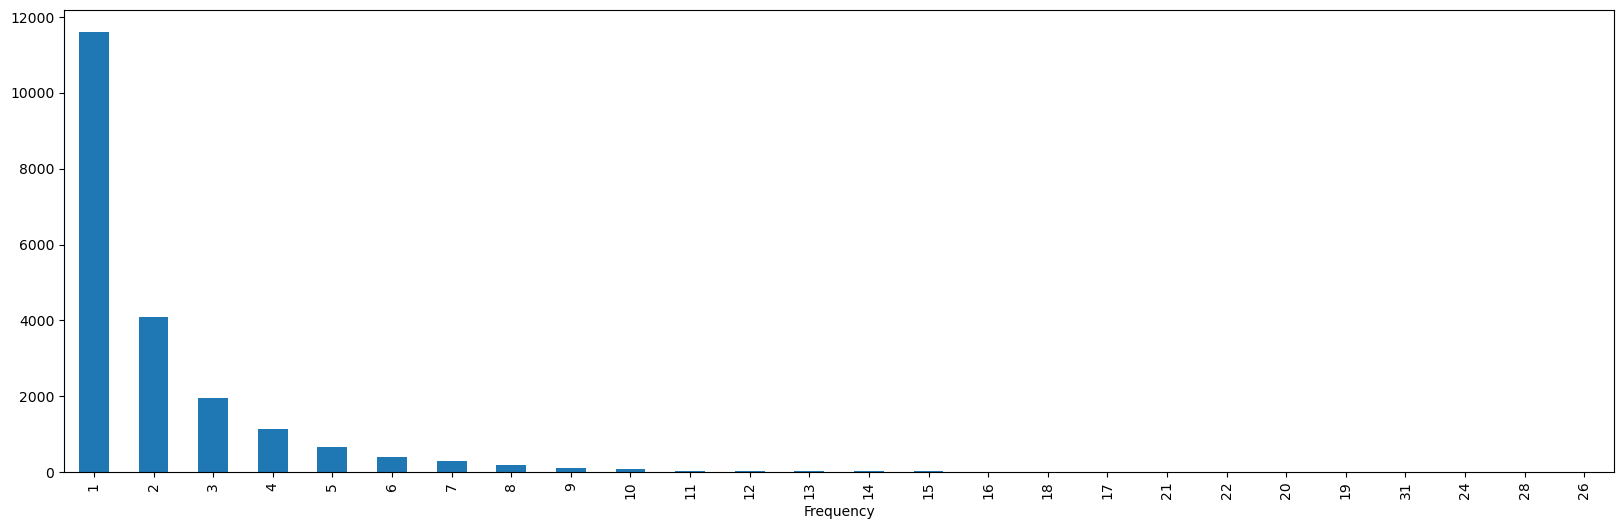

In [168]:
# Graficamos
rfm.Frequency.value_counts().plot(kind = 'bar', figsize = (20,6));

In [169]:
# Porcentaje de clientes que han hecho una sola compra
rfm.Frequency[rfm.Frequency ==1].shape[0]

11606

In [170]:
clientes_una_compra = rfm.Frequency[rfm.Frequency ==1].shape[0]
total_clientes = rfm.shape[0]

(clientes_una_compra / total_clientes) * 100

56.10015467904099

In [171]:
# Frecuencia media de compra entre los clientes
rfm.Frequency.mean()

np.float64(2.109628770301624)

In [172]:
# Clientes que han hecho más de 10 compras
rfm.Frequency[rfm.Frequency >= 10].shape[0]

253

In [173]:
# Porcentaje de clientes que han hecho más de 3 compras
clientes_mas_de_tres_compras = rfm.Frequency[rfm.Frequency > 3].shape[0]

(clientes_mas_de_tres_compras / total_clientes) * 100


14.767014694508894

In [174]:
# Calculamos los 10 clientes más leales
rfm.sort_values('Frequency', ascending = False).head(10)

,Recency,Frequency
ID_Cliente,,
1703,8,31
15942,5,28
17446,32,26
12091,11,24
17757,16,22
10569,8,22
15553,16,22
16192,11,21
13262,10,21


<Axes: xlabel='ID_Cliente'>

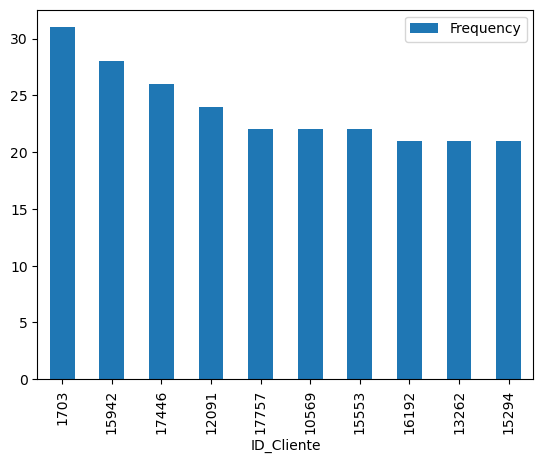

In [175]:
# Graficamos
rfm.sort_values('Frequency', ascending = False).head(10).plot(kind = 'bar', y = 'Frequency')


## Valor Monetario

In [176]:
productos.head()

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario
0,1,2023-01-21,3442,0H2,6OUVC,7.64,4.0,10.50
1,1,2023-01-21,3442,N8U,CEBU8,4.57,4.0,5.79
2,2,2023-03-24,14177,TVL,2SLS0,4.60,3.0,7.77
3,2,2023-06-19,30451,F9B,GZ6VU,9.04,3.0,15.00
4,3,2023-01-01,90,LPF,Y1M2E,3.37,4.0,4.08


In [177]:
# Añadimos la variable Total_Venta como multiplicación entre Cantidad y Precio_Unitario
productos['Total_Venta']= productos['Cantidad'] * productos['Precio_Unitario']

In [178]:
productos.head()

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario,Total_Venta
0,1,2023-01-21,3442,0H2,6OUVC,7.64,4.0,10.50,42.00
1,1,2023-01-21,3442,N8U,CEBU8,4.57,4.0,5.79,23.16
2,2,2023-03-24,14177,TVL,2SLS0,4.60,3.0,7.77,23.31
3,2,2023-06-19,30451,F9B,GZ6VU,9.04,3.0,15.00,45.00
4,3,2023-01-01,90,LPF,Y1M2E,3.37,4.0,4.08,16.32


In [179]:
rfm['Monetary'] = productos.groupby('ID_Cliente')['Total_Venta'].sum()
rfm

,Recency,Frequency,Monetary
ID_Cliente,,,
1,344,1,65.16
2,195,2,68.31
3,364,1,24.60
4,52,2,139.85
5,179,5,143.81
...,...,...,...
22621,21,1,31.26
22622,15,1,18.21
22623,10,1,365.25


In [180]:
rfm.Monetary.describe()

count    20688.000000
mean       103.819227
std        107.361102
min          0.690000
25%         28.020000
50%         61.920000
75%        141.297500
max        500.000000
Name: Monetary, dtype: float64

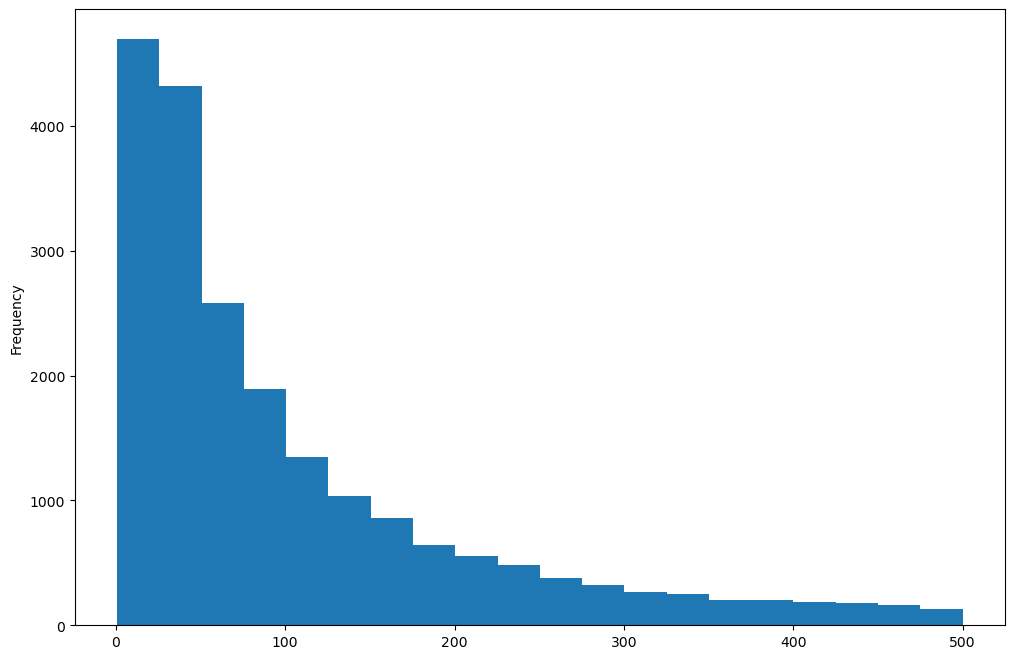

In [181]:
# Graficamos
rfm.Monetary.plot(kind = 'hist', bins = 20, figsize = (12,8));

In [182]:
# Gasto medio de los clientes
rfm.Monetary.mean()

np.float64(103.81922660479506)

In [183]:
# Clientes que más gastan
rfm.sort_values('Monetary',ascending = False).head(50)

,Recency,Frequency,Monetary
ID_Cliente,,,
628,297,1,500.00
7463,258,5,499.95
12807,53,2,499.92
11381,12,2,499.78
1552,305,5,499.68
10624,19,14,499.63
21580,2,5,499.62
13273,57,8,499.34
17779,30,12,499.27


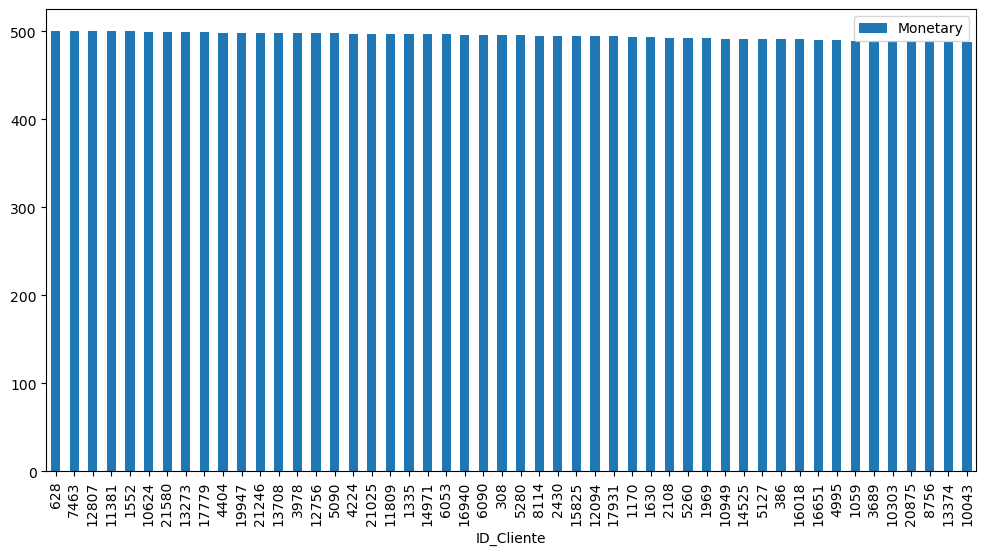

In [184]:
# Graficamos
rfm.sort_values('Monetary', ascending = False).head(50).plot(kind = 'bar', y = 'Monetary', figsize = (12,6));

In [185]:
# Porcentaje de los clientes que generan el 80 % de los ingresos (Pareto)

# Cálculo del ingreso total
ingreso_total = rfm['Monetary'].sum()

# Ordenamos monetary de mayor a menor
rfm_ord = rfm.sort_values('Monetary',ascending = False)

#Calcular suma acumulada de los ingresos de los clientes
rfm_ord['Monetary_acumulado'] = rfm_ord['Monetary'].cumsum() 

# Clientes que representan el 80%
clientes_80_ingreso = rfm_ord[rfm_ord['Monetary_acumulado'] <= 0.8 * ingreso_total]

print(f"Número de clientes que generan el 80 % de los ingresos es: {len(clientes_80_ingreso)}");
# Mostrar clientes
clientes_80_ingreso.head()

Número de clientes que generan el 80 % de los ingresos es: 8624


,Recency,Frequency,Monetary,Monetary_acumulado
ID_Cliente,,,,
628,297,1,500.00,500.00
7463,258,5,499.95,999.95
12807,53,2,499.92,1499.87
11381,12,2,499.78,1999.65
1552,305,5,499.68,2499.33


**Asignación de puntuaciones (Recency)**

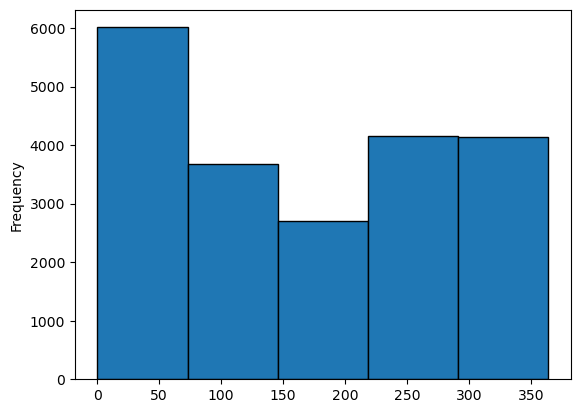

In [186]:
rfm.Recency.plot(kind = 'hist', bins = 5, edgecolor = 'black');

<Axes: xlabel='Recency'>

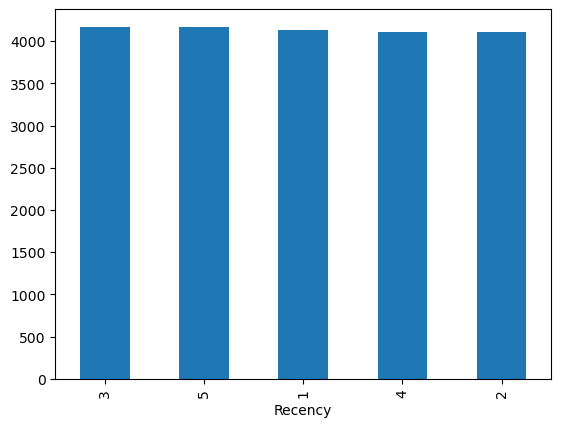

In [187]:
pd.qcut(rfm['Recency'],q = 5, labels = [5,4,3,2,1]).value_counts().plot(kind = 'bar')

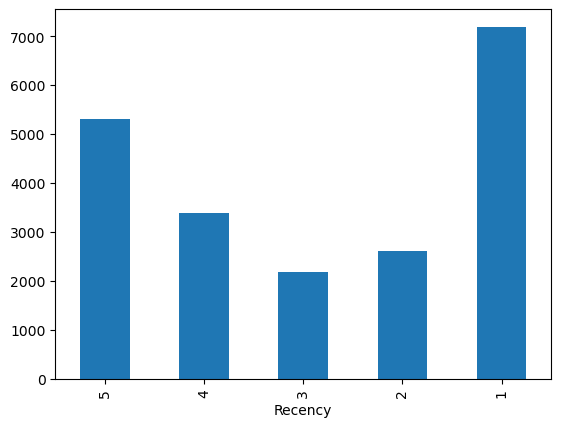

In [188]:
# Como vemos que deja las barras iguales, aplicamos...
corte_prueba_r = pd.cut(rfm['Recency'],bins = [0,60,120,180,240, rfm['Recency'].max()], labels = [5,4,3,2,1], include_lowest = True)
corte_prueba_r.value_counts(sort = False).plot(kind = 'bar');

In [189]:
#pd.cut(rfm['Recency'],bins = [0,60,120,180,240, rfm['Recency'].max()], labels = [5,4,3,2,1], include_lowest = True)

**Asignación puntuaciones (Frequency)**

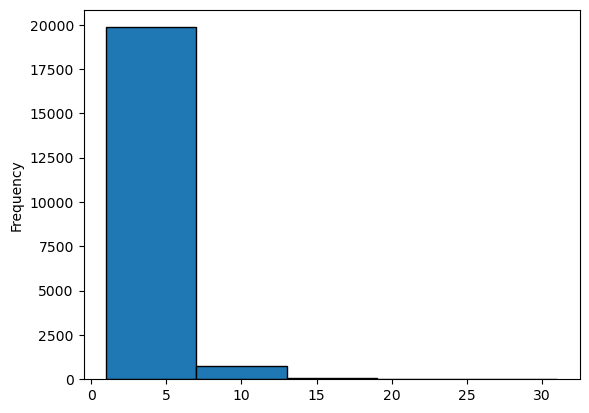

In [190]:
rfm.Frequency.plot(kind = 'hist', bins = 5, edgecolor = 'black');

In [191]:
rfm.Frequency.describe()

count    20688.000000
mean         2.109629
std          1.983245
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         31.000000
Name: Frequency, dtype: float64

<Axes: xlabel='Frequency'>

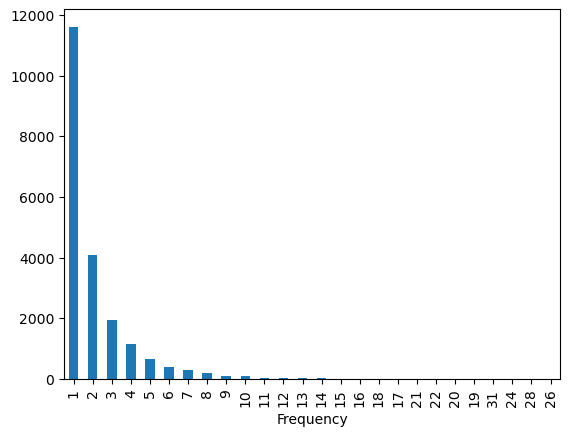

In [192]:
rfm.Frequency.value_counts().plot(kind = 'bar')

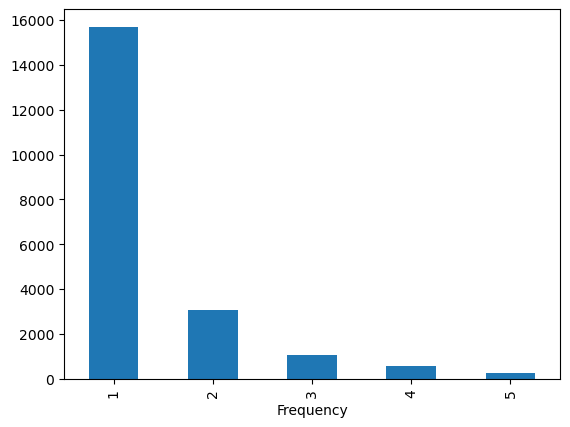

In [193]:
corte_prueba_f = pd.cut(rfm['Frequency'],bins = [1,2,4,6,9, rfm['Frequency'].max()], labels = [1,2,3,4,5], include_lowest = True)
corte_prueba_f.value_counts(sort = False).plot(kind = 'bar');

In [194]:
# pd.cut(rfm['Frequency'],bins = [1,2,4,6,9, rfm['Frequency'].max()], labels = [1,2,3,4,5], include_lowest = True)

**Asignación puntuación (Monetary)**

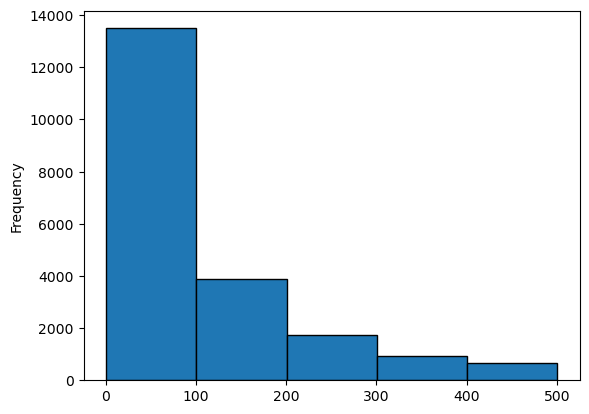

In [195]:
rfm.Monetary.plot(kind = 'hist', bins = 5, edgecolor = 'black');

In [196]:
rfm.Monetary.describe()

count    20688.000000
mean       103.819227
std        107.361102
min          0.690000
25%         28.020000
50%         61.920000
75%        141.297500
max        500.000000
Name: Monetary, dtype: float64

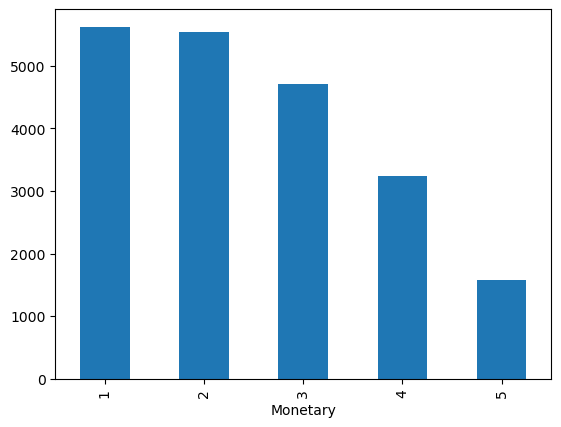

In [197]:
corte_prueba_m = pd.cut(rfm['Monetary'],bins = [0,30,70,150,300, rfm['Monetary'].max()], labels = [1,2,3,4,5], include_lowest = True)
corte_prueba_m.value_counts(sort = False).plot(kind = 'bar');

In [198]:
#pd.cut(rfm['Monetary'],bins = [0,30,70,150,300, rfm['Monetary'].max()], labels = [1,2,3,4,5], include_lowest = True)

**Creación de tabla RFM con puntuaciones**

In [199]:
rfm['r'] = pd.cut(rfm['Recency'],bins = [0,60,120,180,240, rfm['Recency'].max()], labels = [5,4,3,2,1], include_lowest = True)
rfm['f'] = pd.cut(rfm['Frequency'],bins = [1,2,4,6,9, rfm['Frequency'].max()], labels = [1,2,3,4,5], include_lowest = True)
rfm ['m'] = pd.cut(rfm['Monetary'],bins = [0,30,70,150,300, rfm['Monetary'].max()], labels = [1,2,3,4,5], include_lowest = True)

In [200]:
rfm.head()

,Recency,Frequency,Monetary,r,f,m
ID_Cliente,,,,,,
1,344,1,65.16,1,1,2
2,195,2,68.31,2,1,2
3,364,1,24.60,1,1,1
4,52,2,139.85,5,1,3
5,179,5,143.81,3,3,3


In [201]:
# Creamos una nueva variable
# rfm['RFM']= rfm['r'] + rfm['f']+ rfm['m']
# rfm.head()

In [202]:
rfm.info()

<class 'pandas.DataFrame'>
Index: 20688 entries, 1 to 22625
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   Recency    20688 non-null  int64   
 1   Frequency  20688 non-null  int64   
 2   Monetary   20688 non-null  float64 
 3   r          20688 non-null  category
 4   f          20688 non-null  category
 5   m          20688 non-null  category
dtypes: category(3), float64(1), int64(2)
memory usage: 707.2 KB


In [203]:
# Vemos que al ser variables categóricas no nos deja suamrlas, por lo que hacemos el siguiente cambio:
rfm['RFM']= rfm['r'].astype(str) + rfm['f'].astype(str)+ rfm['m'].astype(str)
rfm.head()

,Recency,Frequency,Monetary,r,f,m,RFM
ID_Cliente,,,,,,,
1,344,1,65.16,1,1,2,112
2,195,2,68.31,2,1,2,212
3,364,1,24.60,1,1,1,111
4,52,2,139.85,5,1,3,513
5,179,5,143.81,3,3,3,333


In [204]:
# Consulta sobre puntuaciones, por ejemplo para 111
rfm[rfm['RFM']== '111']
# Debido a que tenemos 125 posibilidades esto no es operativo, y haremos segmentos personalizados

,Recency,Frequency,Monetary,r,f,m,RFM
ID_Cliente,,,,,,,
3,364,1,24.60,1,1,1,111
11,337,1,12.70,1,1,1,111
15,357,1,11.46,1,1,1,111
18,346,1,7.60,1,1,1,111
22,351,1,13.50,1,1,1,111
...,...,...,...,...,...,...,...
21925,242,1,16.76,1,1,1,111
22127,253,1,12.56,1,1,1,111
22128,244,1,18.93,1,1,1,111


**Segmentos personalizados**

In [205]:
def segmentar_clientes(fila):
    r, f, m = str(fila['r']), str(fila['f']), str(fila['m'])
    
    # Definir condiciones previamente para simplificar el código
    es_alto_r = r in ['4', '5']
    es_alto_f = f in ['4', '5']
    es_alto_m = m in ['4', '5']
    
    es_medio_r = r in ['3']
    es_medio_f = f in ['3']
    es_medio_m = m in ['3']
    
    es_bajo_r = r in ['1', '2']
    es_bajo_f = f in ['1', '2']
    es_bajo_m = m in ['1', '2']
    
    # Aplicar la lógica de los segmentos
    if es_alto_r and es_alto_f and es_alto_m:
        return 'Campeones'
    elif es_alto_r and es_alto_f and (es_alto_m or es_medio_m):
        return 'Clientes Leales'
    elif es_medio_r and es_alto_f and es_alto_m:
        return 'Clientes Rentables'
    elif es_bajo_r and es_medio_f and es_medio_m:
        return 'Leales Potenciales'
    elif es_bajo_r and es_bajo_f and es_alto_m:
        return 'Grandes Gastadores'
    elif es_alto_r and es_bajo_f and es_bajo_m:
        return 'Clientes Recientes'
    elif es_medio_r and es_medio_f and es_medio_m:
        return 'Prometedores'
    elif es_bajo_r and es_bajo_f and es_bajo_m:
        return 'En Riesgo'
    else:
        return 'Dudosos'
# Aplicar la función
rfm['Segmento'] = rfm.apply(segmentar_clientes, axis=1)

In [206]:
rfm

,Recency,Frequency,Monetary,r,f,m,RFM,Segmento
ID_Cliente,,,,,,,,
1,344,1,65.16,1,1,2,112,En Riesgo
2,195,2,68.31,2,1,2,212,En Riesgo
3,364,1,24.60,1,1,1,111,En Riesgo
4,52,2,139.85,5,1,3,513,Dudosos
5,179,5,143.81,3,3,3,333,Prometedores
...,...,...,...,...,...,...,...,...
22621,21,1,31.26,5,1,2,512,Clientes Recientes
22622,15,1,18.21,5,1,1,511,Clientes Recientes
22623,10,1,365.25,5,1,5,515,Dudosos


**Consultas sobre RFM**

In [207]:
# Distribución de los segmentos 
rfm['Segmento'].value_counts()

Segmento
Dudosos               8621
En Riesgo             5951
Clientes Recientes    3933
Grandes Gastadores    1409
Campeones              582
Clientes Leales         67
Leales Potenciales      65
Clientes Rentables      39
Prometedores            21
Name: count, dtype: int64

In [208]:
# Cliente promedio
rfm[['Recency', 'Frequency', 'Monetary']].mean()

Recency      168.527020
Frequency      2.109629
Monetary     103.819227
dtype: float64

In [209]:
# Cliente que está en la mediana
rfm[['Recency', 'Frequency', 'Monetary']].median()

Recency      166.00
Frequency      1.00
Monetary      61.92
dtype: float64

In [210]:
# Total de ventas por segmento
rfm.groupby('Segmento')['Monetary'].sum()

Segmento
Campeones              193377.01
Clientes Leales          7802.28
Clientes Recientes     133473.22
Clientes Rentables      12695.43
Dudosos               1247011.72
En Riesgo              184709.84
Grandes Gastadores     358809.03
Leales Potenciales       7470.30
Prometedores             2463.33
Name: Monetary, dtype: float64

In [211]:
# Venta media por segmento
rfm.groupby('Segmento')['Monetary'].mean()

Segmento
Campeones             332.262904
Clientes Leales       116.451940
Clientes Recientes     33.936745
Clientes Rentables    325.523846
Dudosos               144.648152
En Riesgo              31.038454
Grandes Gastadores    254.655096
Leales Potenciales    114.927692
Prometedores          117.301429
Name: Monetary, dtype: float64

In [212]:
# Porcentaje del total de ingresos que representa cada segmento
total_monetary = rfm['Monetary'].sum()
rfm.groupby('Segmento')['Monetary'].sum() / total_monetary * 100

Segmento
Campeones              9.003441
Clientes Leales        0.363266
Clientes Recientes     6.214380
Clientes Rentables     0.591087
Dudosos               58.059627
En Riesgo              8.599907
Grandes Gastadores    16.705792
Leales Potenciales     0.347810
Prometedores           0.114690
Name: Monetary, dtype: float64

Instalamos squarify para poder hacer Treemaps

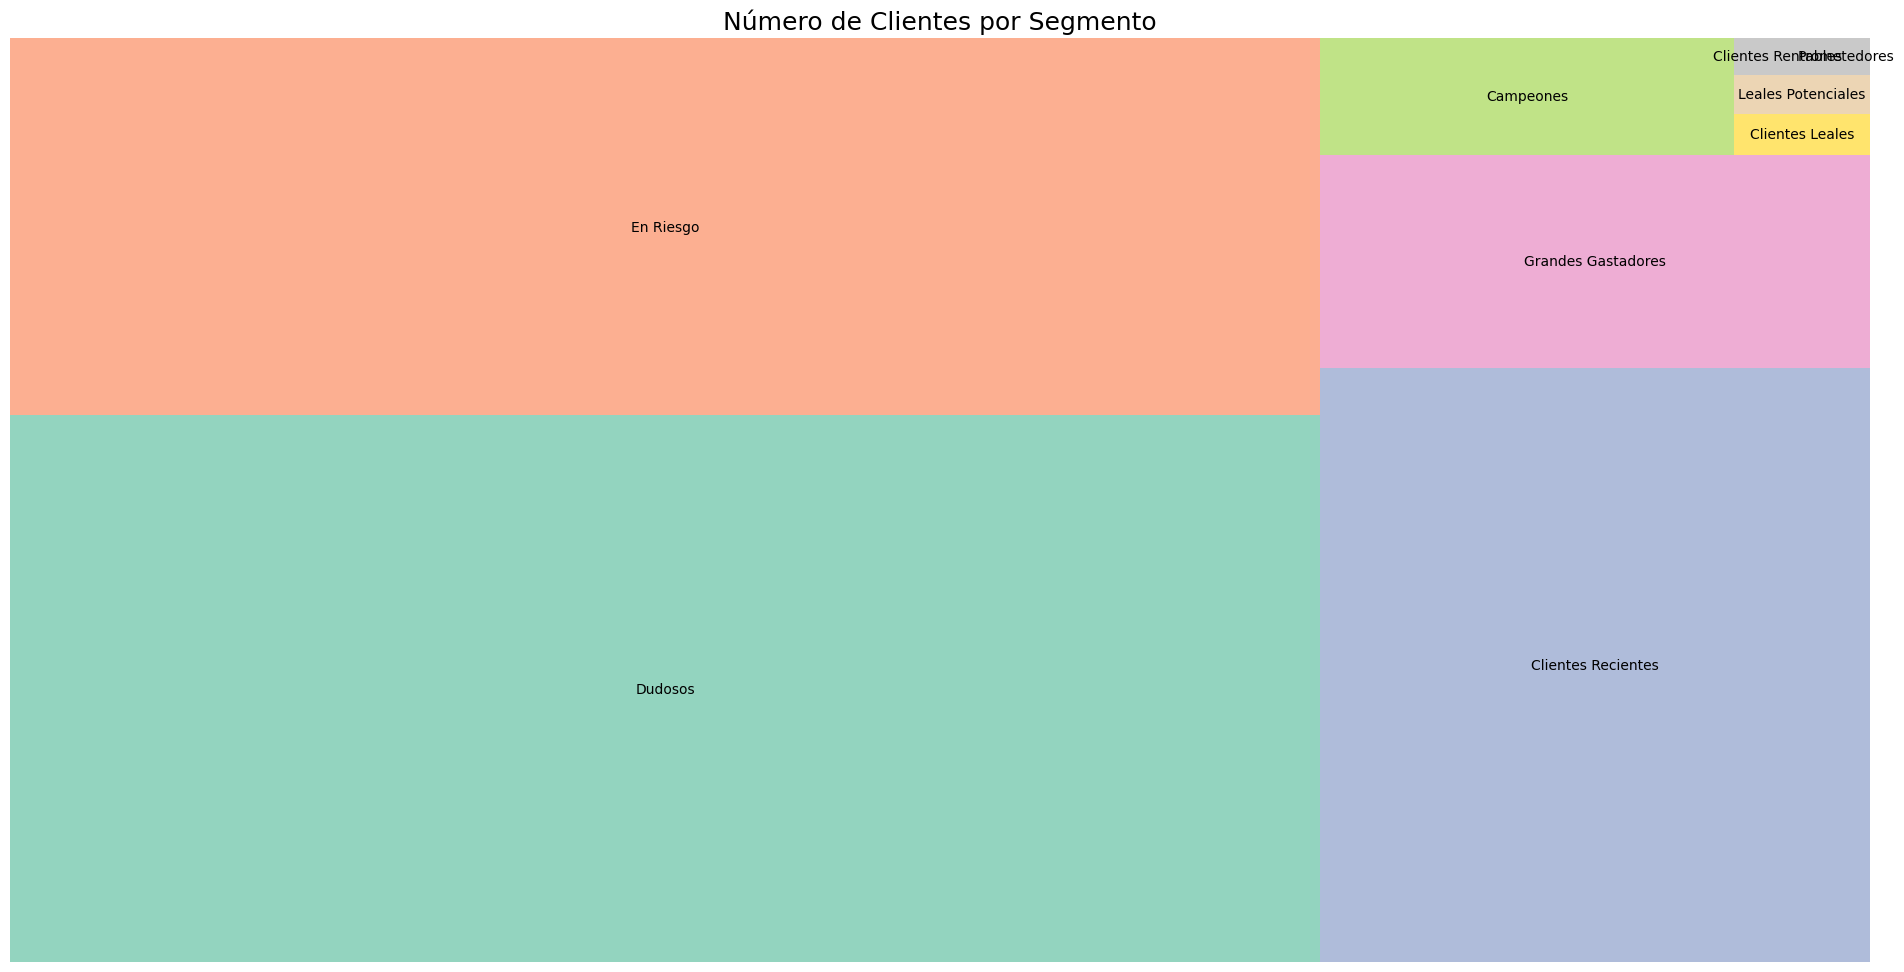

In [213]:
# Representación de clientes por segmento
import squarify
import matplotlib.pyplot as plt

# Contar el número de clientes por segmento
clientes_por_segmento = rfm['Segmento'].value_counts()

# Definir una lista de colores con Matplotlib
cmap = plt.cm.Set2(range(len(clientes_por_segmento)))

# Crear el treemap
plt.figure(figsize=(24, 12))
squarify.plot(sizes=clientes_por_segmento.values, label=clientes_por_segmento.index, color = cmap, alpha =.7, )
    
# Añadir el título y eliminar ejes
plt.title('Número de Clientes por Segmento', fontsize=18)
plt.axis('off')
plt.show()

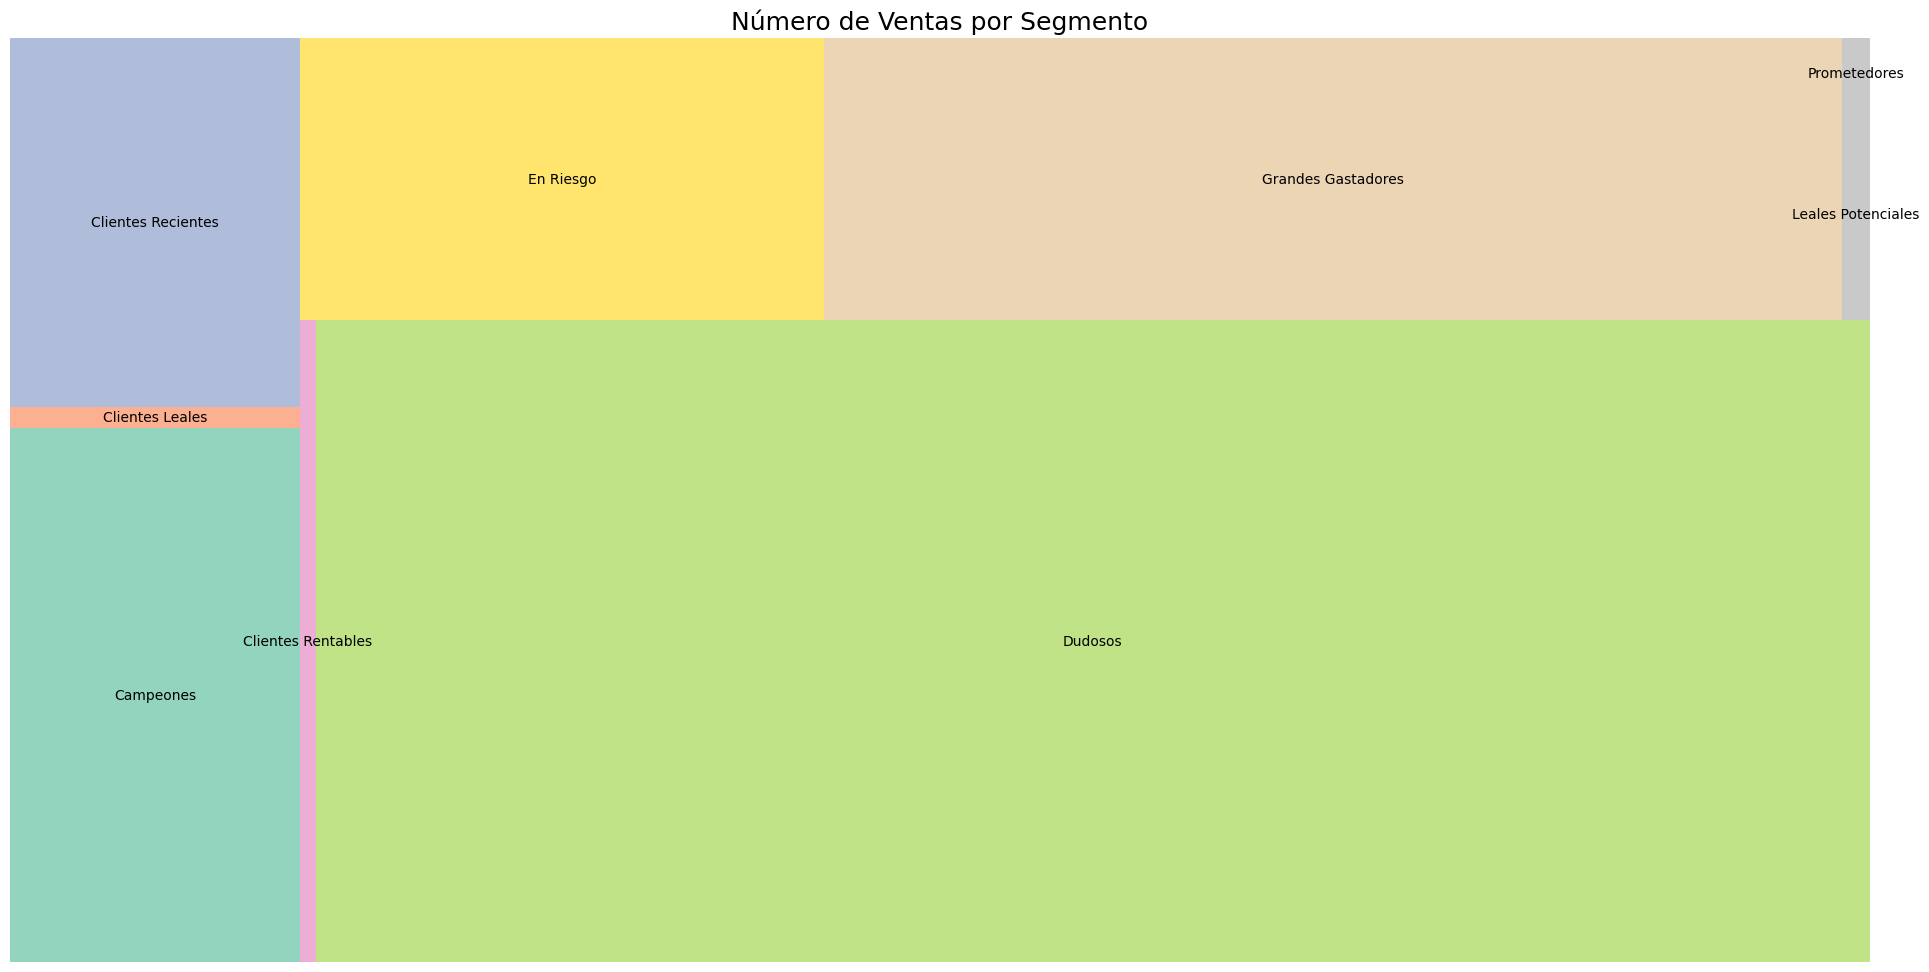

In [214]:
# Graficamos las ventas por segmento

# Contar ventas por segmento
ventas_por_segmento = rfm.groupby('Segmento')['Monetary'].sum()

# Definir una lista de colores con Matplotlib
cmap = plt.cm.Set2(range(len(ventas_por_segmento)))

# Crear el treemap
plt.figure(figsize=(24, 12))
squarify.plot(sizes=ventas_por_segmento, label=ventas_por_segmento.index, color = cmap, alpha =.7, )
    
# Añadir el título y eliminar ejes
plt.title('Número de Ventas por Segmento', fontsize=18)
plt.axis('off')
plt.show()

**Codigo Unificado (que transforman nuestros datos)**

In [ ]:
"""# Obtenemos última fecha de transacción
fecha_max = productos['Fecha'].max()

# Calcular la recencia en dias para cada cliente
rfm = productos.groupby('ID_Cliente').agg(Recency=('Fecha', lambda x: (fecha_max - x.max()).days))

# Cálculo Frequency
rfm['Frequency']= productos.groupby('ID_Cliente')['ID_Transaccion'].nunique()

# Cálculo Monetary
rfm['Monetary'] = productos.groupby('ID_Cliente')['Total_Venta'].sum()

# Puntuaciones RFM
rfm['r'] = pd.cut(rfm['Recency'],bins = [0,60,120,180,240, rfm['Recency'].max()], labels = [5,4,3,2,1], include_lowest = True)
rfm['f'] = pd.cut(rfm['Frequency'],bins = [1,2,4,6,9, rfm['Frequency'].max()], labels = [1,2,3,4,5], include_lowest = True)
rfm ['m'] = pd.cut(rfm['Monetary'],bins = [0,30,70,150,300, rfm['Monetary'].max()], labels = [1,2,3,4,5], include_lowest = True)

# Segmentos personalizados
def segmentar_clientes(fila):
    r, f, m = str(fila['r']), str(fila['f']), str(fila['m'])
    
    # Definir condiciones previamente para simplificar el código
    es_alto_r = r in ['4', '5']
    es_alto_f = f in ['4', '5']
    es_alto_m = m in ['4', '5']
    
    es_medio_r = r in ['3']
    es_medio_f = f in ['3']
    es_medio_m = m in ['3']
    
    es_bajo_r = r in ['1', '2']
    es_bajo_f = f in ['1', '2']
    es_bajo_m = m in ['1', '2']
    
    # Aplicar la lógica de los segmentos
    if es_alto_r and es_alto_f and es_alto_m:
        return 'Campeones'
    elif es_alto_r and es_alto_f and (es_alto_m or es_medio_m):
        return 'Clientes Leales'
    elif es_medio_r and es_alto_f and es_alto_m:
        return 'Clientes Rentables'
    elif es_bajo_r and es_medio_f and es_medio_m:
        return 'Leales Potenciales'
    elif es_bajo_r and es_bajo_f and es_alto_m:
        return 'Grandes Gastadores'
    elif es_alto_r and es_bajo_f and es_bajo_m:
        return 'Clientes Recientes'
    elif es_medio_r and es_medio_f and es_medio_m:
        return 'Prometedores'
    elif es_bajo_r and es_bajo_f and es_bajo_m:
        return 'En Riesgo'
    else:
        return 'Dudosos'
# Aplicar la función
rfm['Segmento'] = rfm.apply(segmentar_clientes, axis=1)
"""

# Propuesta de acción de márketing
**1. Campaña de Reactivación:** Dirigida a clientes inactivos o en riesgo, ofreciéndoles incentivos para volver a comprar.
* En Riesgo: Clientes con baja recencia, frecuencia y valor monetario. Son clientes que probablemente han dejado de comprar por completo.
* Dudosos: Son clientes que no han mostrado un patrón consistente, y es probable que estén inactivos o a punto de perderse.

**2. Campaña de Conversión de Compradores Únicos:** Motivar a los clientes que han comprado solo una vez a convertirse en recurrentes mediante ofertas y seguimiento personalizado.
* Clientes Recientes: Compraron por primera vez recientemente, pero no han repetido compra.
* Prometedores: Clientes con valores medios en todas las métricas. Han mostrado interés, pero aún no han demostrado lealtad o valor alto.
* Clientes Rentables: Compran con frecuencia y gastan bien, pero podrían no haber comprado recientemente.

**3. Campaña de Upselling/Cross-selling:** Aumentar el valor promedio de compra mediante paquetes, productos premium y descuentos por gasto mínimo.
* Clientes Rentables: Compran con frecuencia y gastan bastante, pero pueden no estar comprando productos de mayor valor.
* Leales Potenciales: Han sido consistentes, pero con un valor monetario moderado. Pueden ser incentivados a gastar más.
* Grandes Gastadores: Compran de forma esporádica, pero cuando lo hacen, gastan mucho. Estos clientes podrían comprar con mayor frecuencia o agregar más productos a su carrito.

**1. Campaña de Reactivación**

In [215]:
# Filtrar clientes inactivos 
segmentos_reactivacion = ['En Riesgo','Dudosos']

# Filtrar los clientes pertenecientes a estos segmentos
clientes_inactivos = rfm[rfm['Segmento'].isin(segmentos_reactivacion)]
clientes_inactivos

,Recency,Frequency,Monetary,r,f,m,RFM,Segmento
ID_Cliente,,,,,,,,
1,344,1,65.16,1,1,2,112,En Riesgo
2,195,2,68.31,2,1,2,212,En Riesgo
3,364,1,24.60,1,1,1,111,En Riesgo
4,52,2,139.85,5,1,3,513,Dudosos
6,275,1,91.66,1,1,3,113,Dudosos
...,...,...,...,...,...,...,...,...
22617,19,1,84.48,5,1,3,513,Dudosos
22618,164,1,9.54,3,1,1,311,Dudosos
22623,10,1,365.25,5,1,5,515,Dudosos


**2.Campaña de Conversión de Compradores Únicos:**

In [216]:
# Filtrar clientes con baja o mediana frecuencia 
segmentos_conversion = ['Clientes Recientes', 'Prometedores', 'Clientes Rentables']

# Filtrar los clientes pertenecientes a estos segmentos
clientes_conversion = rfm[rfm['Segmento'].isin(segmentos_conversion)]
clientes_conversion

,Recency,Frequency,Monetary,r,f,m,RFM,Segmento
ID_Cliente,,,,,,,,
5,179,5,143.81,3,3,3,333,Prometedores
7,87,1,53.52,4,1,2,412,Clientes Recientes
23,101,1,5.52,4,1,1,411,Clientes Recientes
84,134,6,82.80,3,3,3,333,Prometedores
108,93,2,43.16,4,1,2,412,Clientes Recientes
...,...,...,...,...,...,...,...,...
22616,66,1,12.06,4,1,1,411,Clientes Recientes
22619,27,1,18.54,5,1,1,511,Clientes Recientes
22620,60,1,43.00,5,1,2,512,Clientes Recientes


**3. Campaña de Upselling/Cross-selling**

In [217]:
# Filtrar clientes con potencial de aumento de gasto 
segmentos_upselling = ['Clientes Rentables', 'Leales Potenciales', 'Grandes Gastadores']

# Filtrar los clientes pertenecientes a estos segmentos
clientes_upselling = rfm[rfm['Segmento'].isin(segmentos_upselling)]
clientes_upselling

,Recency,Frequency,Monetary,r,f,m,RFM,Segmento
ID_Cliente,,,,,,,,
10,323,1,220.62,1,1,4,114,Grandes Gastadores
13,324,2,159.72,1,1,4,114,Grandes Gastadores
14,311,3,402.42,1,2,5,125,Grandes Gastadores
16,257,2,310.80,1,1,5,115,Grandes Gastadores
19,262,1,199.90,1,1,4,114,Grandes Gastadores
...,...,...,...,...,...,...,...,...
21804,187,1,213.91,2,1,4,214,Grandes Gastadores
21883,198,1,159.12,2,1,4,214,Grandes Gastadores
21958,227,1,158.85,2,1,4,214,Grandes Gastadores
